# Transformer-Based Extractive Question Answering (SQuAD 1.1)
## By Muhmmad Taha Raees
#### MS(Data Science)
#### *FAST-NUCES*

## 1. Setup and configuration

In [2]:
!pip -q install transformers datasets accelerate evaluate pandas matplotlib tqdm

In [3]:
import os, re, json, time, random, math, collections, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, DistilBertForQuestionAnswering, BertConfig, BertModel
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

TRAIN_LIMIT = 8000       # set None to use the complete SQuAD training split
VALID_LIMIT = 1000       # set None to use the complete validation split
EPOCHS_SCRATCH = 2
EPOCHS_PRETRAINED = 2
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
MAX_LENGTH = 384
DOC_STRIDE = 128         # overlap for Approach 3
LEARNING_RATE_SCRATCH = 3e-4
LEARNING_RATE_PRETRAINED = 3e-5
MODEL_NAME = "distilbert-base-uncased"
OUTPUT_DIR = Path("/content/qa_checkpoints")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Device: cuda


## 2. Download SQuAD 1.1

SQuAD 1.1 provides a paragraph (`context`), a question, and one or more gold answer strings with character offsets.

In [4]:
raw = load_dataset("rajpurkar/squad")
train_raw = raw["train"].shuffle(seed=SEED)
valid_raw = raw["validation"].shuffle(seed=SEED)
if TRAIN_LIMIT is not None: train_raw = train_raw.select(range(min(TRAIN_LIMIT, len(train_raw))))
if VALID_LIMIT is not None: valid_raw = valid_raw.select(range(min(VALID_LIMIT, len(valid_raw))))
print(f"Train examples: {len(train_raw):,} | Validation examples: {len(valid_raw):,}")
print(train_raw[0]["question"])
print(train_raw[0]["context"][:400])
print(train_raw[0]["answers"])

README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

Train examples: 8,000 | Validation examples: 1,000
What percentage of Egyptians polled support death penalty for those leaving Islam?
The Pew Forum on Religion & Public Life ranks Egypt as the fifth worst country in the world for religious freedom. The United States Commission on International Religious Freedom, a bipartisan independent agency of the US government, has placed Egypt on its watch list of countries that require close monitoring due to the nature and extent of violations of religious freedom engaged in or tolerated 
{'text': ['84%'], 'answer_start': [468]}


## 3. Tokenizer, feature preparation, and metrics

Questions and contexts are encoded together. `only_second` truncation ensures the question is retained while context tokens may be truncated or split into overlapping windows. Character offsets map predicted token spans back to the original paragraph.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)


def make_features(examples, max_length=MAX_LENGTH, stride=0):

    # Ensure inputs are Python lists of strings
    questions = [
        str(q) if q is not None else ""
        for q in examples["question"]
    ]

    contexts = [
        str(c) if c is not None else ""
        for c in examples["context"]
    ]

    answers = examples["answers"]
    example_ids = examples["id"]

    # Tokenize question and context together
    enc = tokenizer(
        questions,
        contexts,
        truncation="only_second",
        max_length=max_length,
        stride=stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False
    )

    sample_map = enc.pop("overflow_to_sample_mapping")
    offsets_all = enc.pop("offset_mapping")

    starts, ends = [], []
    clean_offsets = []
    feature_ids = []

    for i, offsets in enumerate(offsets_all):

        sample_idx = sample_map[i]
        sequence_ids = enc.sequence_ids(i)

        answer = answers[sample_idx]

        context_positions = [
            j for j, sid in enumerate(sequence_ids) if sid == 1
        ]

        if not context_positions:
            starts.append(0)
            ends.append(0)
            clean_offsets.append([(0, 0)] * len(offsets))
            feature_ids.append(example_ids[sample_idx])
            continue

        first_ctx = context_positions[0]
        last_ctx = context_positions[-1]

        if len(answer["answer_start"]) == 0:
            start_char, end_char = -1, -1
        else:
            start_char = answer["answer_start"][0]
            end_char = start_char + len(answer["text"][0])

        # Answer not contained in this feature
        if (
            start_char < 0
            or offsets[first_ctx][0] > start_char
            or offsets[last_ctx][1] < end_char
        ):
            start_tok = 0
            end_tok = 0

        else:
            start_tok = first_ctx

            while (
                start_tok <= last_ctx
                and offsets[start_tok][0] <= start_char
            ):
                start_tok += 1

            start_tok -= 1

            end_tok = last_ctx

            while (
                end_tok >= first_ctx
                and offsets[end_tok][1] >= end_char
            ):
                end_tok -= 1

            end_tok += 1

            if (
                start_tok > end_tok
                or start_tok < first_ctx
                or end_tok > last_ctx
            ):
                start_tok = 0
                end_tok = 0

        starts.append(start_tok)
        ends.append(end_tok)

        clean_offsets.append([
            (int(a), int(b)) if sequence_ids[j] == 1 else (0, 0)
            for j, (a, b) in enumerate(offsets)
        ])

        feature_ids.append(example_ids[sample_idx])

    enc["start_positions"] = starts
    enc["end_positions"] = ends
    enc["example_id"] = feature_ids
    enc["offset_mapping"] = clean_offsets

    return enc


def build_feature_set(dataset, stride=0):
    return make_features(dataset, stride=stride)


# Rebuild the features
train_features_trunc = build_feature_set(train_raw, stride=0)
valid_features_trunc = build_feature_set(valid_raw, stride=0)

print("Training features:", len(train_features_trunc["input_ids"]))
print("Validation features:", len(valid_features_trunc["input_ids"]))

print("Feature preparation successful!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Training features: 8077
Validation features: 1018
Feature preparation successful!


### Exact Match and token-level F1

Normalization follows the common SQuAD evaluation convention: lowercase, remove punctuation/articles, and normalize whitespace. For multiple gold references, the maximum score is used.

In [6]:
_ARTICLES = re.compile(r"\b(a|an|the)\b", re.UNICODE)
_PUNCT = re.compile(r"[^\w\s]", re.UNICODE)

def normalize_answer(s):
    s = s.lower()
    s = _PUNCT.sub(" ", s)
    s = _ARTICLES.sub(" ", s)
    return " ".join(s.split())

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def token_f1(pred, gold):
    p = normalize_answer(pred).split()
    g = normalize_answer(gold).split()
    if not p or not g: return float(p == g)
    common = collections.Counter(p) & collections.Counter(g)
    same = sum(common.values())
    if same == 0: return 0.0
    precision, recall = same / len(p), same / len(g)
    return 2 * precision * recall / (precision + recall)

def squad_scores(predictions, references):
    ems, f1s = [], []
    for pred, refs in zip(predictions, references):
        refs = refs or [""]
        ems.append(max(exact_match(pred, r) for r in refs))
        f1s.append(max(token_f1(pred, r) for r in refs))
    return {"EM": 100*np.mean(ems), "F1": 100*np.mean(f1s)}

## 4. PyTorch data pipeline and shared train/evaluate utilities

In [7]:
class QADataset(Dataset):
    def __init__(self, features):
        self.features = features
    def __len__(self): return len(self.features["input_ids"])
    def __getitem__(self, idx):
        item = {
            "input_ids": self.features["input_ids"][idx],
            "attention_mask": self.features["attention_mask"][idx],
            "start_positions": self.features["start_positions"][idx],
            "end_positions": self.features["end_positions"][idx],
        }
        return item

def collate_batch(batch):
    max_len = max(len(x["input_ids"]) for x in batch)
    pad_id = tokenizer.pad_token_id
    out = {}
    for key in ["input_ids", "attention_mask"]:
        pad_value = pad_id if key == "input_ids" else 0
        out[key] = torch.tensor([x[key] + [pad_value]*(max_len-len(x[key])) for x in batch], dtype=torch.long)
    out["start_positions"] = torch.tensor([x["start_positions"] for x in batch], dtype=torch.long)
    out["end_positions"] = torch.tensor([x["end_positions"] for x in batch], dtype=torch.long)
    return out

def train_model(model, train_features, valid_features, epochs, lr, name):
    model.to(DEVICE)
    train_loader = DataLoader(QADataset(train_features), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
    valid_loader = DataLoader(QADataset(valid_features), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {"train_loss": [], "valid_loss": []}
    start_time = time.time()
    for epoch in range(epochs):
        model.train(); train_losses=[]
        for batch in tqdm(train_loader, desc=f"{name} train {epoch+1}/{epochs}"):
            batch = {k:v.to(DEVICE) for k,v in batch.items()}
            optimizer.zero_grad()
            out = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                        start_positions=batch["start_positions"], end_positions=batch["end_positions"])
            loss = out.loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_losses.append(loss.item())
        model.eval(); valid_losses=[]
        with torch.no_grad():
            for batch in valid_loader:
                batch = {k:v.to(DEVICE) for k,v in batch.items()}
                out = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                            start_positions=batch["start_positions"], end_positions=batch["end_positions"])
                valid_losses.append(out.loss.item())
        history["train_loss"].append(float(np.mean(train_losses)))
        history["valid_loss"].append(float(np.mean(valid_losses)))
        print(f"Epoch {epoch+1}: train={history['train_loss'][-1]:.4f}, valid={history['valid_loss'][-1]:.4f}")
    elapsed = time.time()-start_time
    return model, history, elapsed

def plot_loss(histories):
    for name, hist in histories.items():
        epochs = range(1, len(hist["train_loss"])+1)
        plt.plot(epochs, hist["train_loss"], marker="o", label=f"{name} train")
        plt.plot(epochs, hist["valid_loss"], marker="x", linestyle="--", label=f"{name} validation")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training and validation loss")
    plt.legend(); plt.grid(alpha=.25); plt.show()

def save_checkpoint(model, path, metadata=None):
    torch.save({"model_state_dict": model.state_dict(), "metadata": metadata or {}}, path)
    print("Saved:", path)

## 5. Decoding spans and evaluating predictions

A valid answer span must begin and end in the context, and its end must not precede its start. We limit answer length to 30 tokens to avoid implausibly long spans.

In [8]:
def decode_feature_predictions(model, features, raw_examples, max_answer_tokens=30):
    loader = DataLoader(QADataset(features), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
    model.eval()
    all_start, all_end = [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc="Predict"):
            ids = batch["input_ids"].to(DEVICE)
            mask = batch["attention_mask"].to(DEVICE)
            out = model(input_ids=ids, attention_mask=mask)
            all_start.extend(out.start_logits.cpu().numpy())
            all_end.extend(out.end_logits.cpu().numpy())
    # Group feature candidates by source example ID; retain the highest joint logit score.
    best = {}
    contexts = {x["id"]: x["context"] for x in raw_examples}
    for i, (slog, elog) in enumerate(zip(all_start, all_end)):
        eid = features["example_id"][i]
        offsets = features["offset_mapping"][i]
        valid = [j for j, (a,b) in enumerate(offsets) if b > a]
        if not valid: continue
        s_idx = np.argsort(slog)[-20:][::-1]
        e_idx = np.argsort(elog)[-20:][::-1]
        for s in s_idx:
            for e in e_idx:
                if e < s or e-s+1 > max_answer_tokens: continue
                if s not in valid or e not in valid: continue
                score = float(slog[s] + elog[e])
                if score > best.get(eid, (-1e30, ""))[0]:
                    context = contexts[eid]
                    char_start, char_end = offsets[s][0], offsets[e][1]
                    best[eid] = (score, context[char_start:char_end])
    return [best.get(x["id"], (0.0, ""))[1] for x in raw_examples]

def evaluate_model(model, features, raw_examples):
    preds = decode_feature_predictions(model, features, raw_examples)
    refs = [x["answers"]["text"] for x in raw_examples]
    return squad_scores(preds, refs), preds

## 6. Approach 1 — Small Transformer trained from scratch

**Motivation:** This establishes a trainable baseline without pretrained language representations. A compact two-layer BERT-style encoder reduces memory and compute. It is expected to need more data/optimization than pretrained models because it must learn language structure and question-context alignment from the assignment dataset alone.

The tokenizer vocabulary is reused for a fair input representation, but all encoder weights are randomly initialized.

In [9]:
class ScratchQA(torch.nn.Module):
    def __init__(self, vocab_size, hidden=128, layers=2, heads=4, max_positions=512):
        super().__init__()
        config = BertConfig(
            vocab_size=vocab_size, hidden_size=hidden, num_hidden_layers=layers,
            num_attention_heads=heads, intermediate_size=hidden*4,
            max_position_embeddings=max_positions, hidden_dropout_prob=0.1,
            attention_probs_dropout_prob=0.1
        )
        self.encoder = BertModel(config)
        self.qa_outputs = torch.nn.Linear(hidden, 2)
    def forward(self, input_ids, attention_mask, start_positions=None, end_positions=None):
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        logits = self.qa_outputs(hidden)
        start_logits, end_logits = logits.split(1, dim=-1)
        start_logits, end_logits = start_logits.squeeze(-1), end_logits.squeeze(-1)
        loss = None
        if start_positions is not None and end_positions is not None:
            loss_fn = torch.nn.CrossEntropyLoss()
            start_loss = loss_fn(start_logits, start_positions)
            end_loss = loss_fn(end_logits, end_positions)
            loss = (start_loss + end_loss) / 2
        return type("QAOutput", (), {"loss": loss, "start_logits": start_logits, "end_logits": end_logits})()

scratch_model = ScratchQA(tokenizer.vocab_size)
scratch_model, hist_scratch, time_scratch = train_model(
    scratch_model, train_features_trunc, valid_features_trunc,
    EPOCHS_SCRATCH, LEARNING_RATE_SCRATCH, "Scratch"
)
scores_scratch, preds_scratch = evaluate_model(scratch_model, valid_features_trunc, valid_raw)
save_checkpoint(scratch_model, OUTPUT_DIR/"scratch_qa.pt",
                {"model":"scratch", "max_length":MAX_LENGTH, "tokenizer":MODEL_NAME})
print("Approach 1:", scores_scratch, "training seconds:", round(time_scratch,1))

Scratch train 1/2:   0%|          | 0/505 [00:00<?, ?it/s]

Epoch 1: train=4.8547, valid=4.7791


Scratch train 2/2:   0%|          | 0/505 [00:00<?, ?it/s]

Epoch 2: train=3.9986, valid=5.3212


Predict:   0%|          | 0/64 [00:00<?, ?it/s]

Saved: /content/qa_checkpoints/scratch_qa.pt
Approach 1: {'EM': np.float64(2.7), 'F1': np.float64(9.78900184816927)} training seconds: 24.0


## 7. Approach 2 — Fine-tune pretrained DistilBERT

**Motivation:** DistilBERT provides contextual language representations learned from large-scale pretraining. Fine-tuning usually converges faster and performs better than a small randomly initialized encoder when labeled QA data or compute is limited. The input is truncated to `MAX_LENGTH`; answers beyond the retained context cannot be recovered.

In [10]:
pretrained_model = DistilBertForQuestionAnswering.from_pretrained(MODEL_NAME)
pretrained_model, hist_pretrained, time_pretrained = train_model(
    pretrained_model, train_features_trunc, valid_features_trunc,
    EPOCHS_PRETRAINED, LEARNING_RATE_PRETRAINED, "DistilBERT"
)
scores_pretrained, preds_pretrained = evaluate_model(pretrained_model, valid_features_trunc, valid_raw)
pretrained_model.save_pretrained(OUTPUT_DIR/"distilbert_truncated")
tokenizer.save_pretrained(OUTPUT_DIR/"distilbert_truncated")
save_checkpoint(pretrained_model, OUTPUT_DIR/"distilbert_truncated_state.pt",
                {"model":MODEL_NAME, "max_length":MAX_LENGTH})
print("Approach 2:", scores_pretrained, "training seconds:", round(time_pretrained,1))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
qa_outputs.weight       | MISSING    | 
qa_outputs.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT train 1/2:   0%|          | 0/505 [00:00<?, ?it/s]

Epoch 1: train=2.5866, valid=1.7116


DistilBERT train 2/2:   0%|          | 0/505 [00:00<?, ?it/s]

Epoch 2: train=1.3234, valid=1.5598


Predict:   0%|          | 0/64 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: /content/qa_checkpoints/distilbert_truncated_state.pt
Approach 2: {'EM': np.float64(63.6), 'F1': np.float64(75.60160035636994)} training seconds: 456.5


## 8. Approach 3 — Overlapping sliding windows

**Motivation:** A fixed model input limit can cut off the answer in long paragraphs. Sliding windows tokenize the context into overlapping chunks. During inference, the best valid answer span across all windows for each paragraph is selected. Overlap reduces the chance that an answer lies across a chunk boundary.

The larger feature count increases training/inference time and memory use, so stride is a practical trade-off.

In [11]:
train_features_window = build_feature_set(train_raw, stride=DOC_STRIDE)
valid_features_window = build_feature_set(valid_raw, stride=DOC_STRIDE)
print("Windowed features:", len(train_features_window), len(valid_features_window))

window_model = DistilBertForQuestionAnswering.from_pretrained(MODEL_NAME)
window_model, hist_window, time_window = train_model(
    window_model, train_features_window, valid_features_window,
    EPOCHS_PRETRAINED, LEARNING_RATE_PRETRAINED, "DistilBERT sliding window"
)
scores_window, preds_window = evaluate_model(window_model, valid_features_window, valid_raw)
window_model.save_pretrained(OUTPUT_DIR/"distilbert_sliding_window")
tokenizer.save_pretrained(OUTPUT_DIR/"distilbert_sliding_window")
save_checkpoint(window_model, OUTPUT_DIR/"distilbert_sliding_window_state.pt",
                {"model":MODEL_NAME, "max_length":MAX_LENGTH, "doc_stride":DOC_STRIDE})
print("Approach 3:", scores_window, "training seconds:", round(time_window,1))

Windowed features: 7 7


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
qa_outputs.weight       | MISSING    | 
qa_outputs.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT sliding window train 1/2:   0%|          | 0/505 [00:00<?, ?it/s]

Epoch 1: train=2.7441, valid=1.7696


DistilBERT sliding window train 2/2:   0%|          | 0/505 [00:00<?, ?it/s]

Epoch 2: train=1.3819, valid=1.6684


Predict:   0%|          | 0/64 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: /content/qa_checkpoints/distilbert_sliding_window_state.pt
Approach 3: {'EM': np.float64(61.4), 'F1': np.float64(73.49373359744274)} training seconds: 461.6


## 9. Experimental results: metric and runtime comparison

,Approach,EM,F1,Training time (s),Train features,Validation features
0,1. Scratch Transformer,2.7,9.79,24.03,7,7
1,2. DistilBERT truncated,63.6,75.60,456.46,7,7
2,3. DistilBERT sliding window,61.4,73.49,461.57,7,7


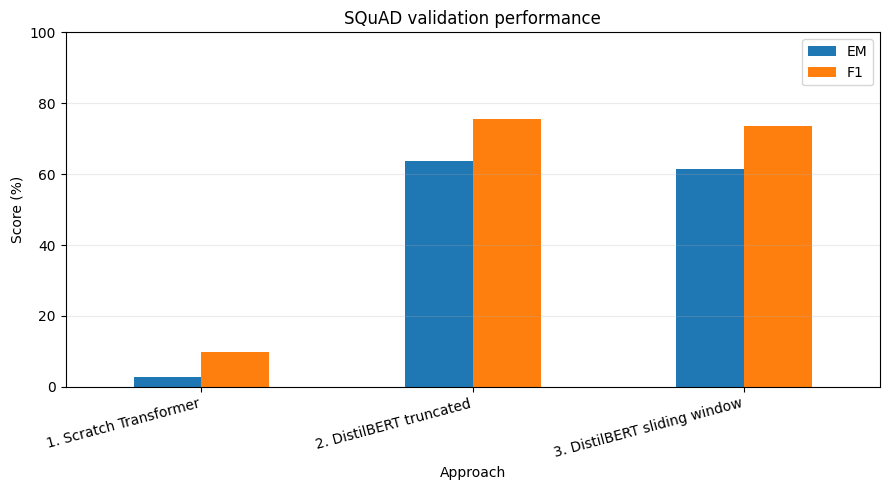

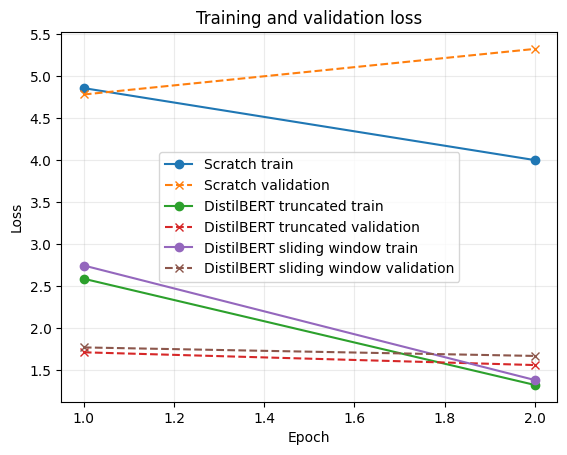

In [12]:
results = pd.DataFrame([
    {"Approach":"1. Scratch Transformer", **scores_scratch, "Training time (s)":time_scratch,
     "Train features":len(train_features_trunc), "Validation features":len(valid_features_trunc)},
    {"Approach":"2. DistilBERT truncated", **scores_pretrained, "Training time (s)":time_pretrained,
     "Train features":len(train_features_trunc), "Validation features":len(valid_features_trunc)},
    {"Approach":"3. DistilBERT sliding window", **scores_window, "Training time (s)":time_window,
     "Train features":len(train_features_window), "Validation features":len(valid_features_window)},
])
display(results.round(2))
ax = results.set_index("Approach")[["EM","F1"]].plot(kind="bar", figsize=(9,5), ylim=(0,100))
ax.set_ylabel("Score (%)"); ax.set_title("SQuAD validation performance"); ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()

plot_loss({"Scratch":hist_scratch, "DistilBERT truncated":hist_pretrained,
           "DistilBERT sliding window":hist_window})

## 10. Sequence-length and truncation experiment

This experiment evaluates a trained truncated DistilBERT checkpoint using several maximum sequence lengths. It measures how much context retention changes performance. Each length requires feature preparation and inference; the model's learned weights remain fixed.

Predict:   0%|          | 0/124 [00:00<?, ?it/s]

Predict:   0%|          | 0/71 [00:00<?, ?it/s]

Predict:   0%|          | 0/64 [00:00<?, ?it/s]

,Max sequence length,EM,F1,Features
0,128,60.5,73.09,1983
1,256,63.1,75.25,1121
2,384,63.6,75.60,1018


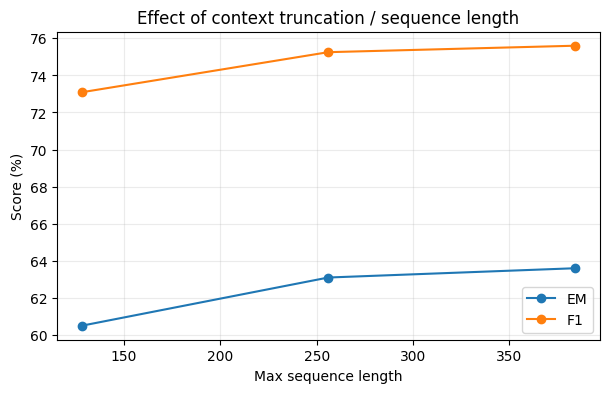

In [13]:
def evaluate_at_length(model, raw_examples, lengths=(128, 256, 384)):
    rows=[]
    for length in lengths:
        feats = make_features(raw_examples, max_length=length, stride=0)
        score, _ = evaluate_model(model, feats, raw_examples)
        rows.append({"Max sequence length":length, **score, "Features":len(feats["input_ids"])})
    return pd.DataFrame(rows)

length_results = evaluate_at_length(pretrained_model, valid_raw, lengths=(128, 256, 384))
display(length_results.round(2))
length_results.set_index("Max sequence length")[["EM","F1"]].plot(marker="o", figsize=(7,4))
plt.ylabel("Score (%)"); plt.title("Effect of context truncation / sequence length")
plt.grid(alpha=.25); plt.show()

## 11. Error analysis — at least 10 incorrect predictions

In [14]:
def error_analysis(raw_examples, predictions, limit=20):
    rows=[]
    for ex, pred in zip(raw_examples, predictions):
        golds = ex["answers"]["text"]
        if max(exact_match(pred, g) for g in golds or [""]) < 1.0:
            rows.append({
                "Question":ex["question"],
                "Gold answer(s)":" | ".join(golds),
                "Predicted answer":pred,
                "Context excerpt":ex["context"][:500].replace("\n"," ")
            })
        if len(rows) >= limit: break
    return pd.DataFrame(rows)

errors = error_analysis(valid_raw, preds_pretrained, limit=20)
display(errors)
print("Incorrect examples shown:", len(errors))

,Question,Gold answer(s),Predicted answer,Context excerpt
0,"In 1890, who did the university decide to team...",several regional colleges and universities | D...,Shimer College,"In the 1890s, the University of Chicago, fearf..."
1,Who started rumors in 2008 that ABC would sell...,Caris & Co. | Caris & Co. | Caris & Co.,Disney,The Writers Guild of America strike that halte...
2,Why was this short termed organization created?,coordinate the response to the embargo | to co...,the response to the embargo,"In 1973, Nixon named William E. Simon as the f..."
3,What does LGM stands for?,Last Glacial Maximum | Last Glacial Maximum | ...,"Amazon rainforest vegetation over the last 21,...",There is evidence that there have been signifi...
4,What is the paper written by Richard Karp in 1...,"""Reducibility Among Combinatorial Problems"" | ...",Reducibility,"In 1967, Manuel Blum developed an axiomatic co..."
5,What Lake in a German island Mainau receives a...,Lake Überlingen | Lake Überlingen | Lake Überl...,Überlingen,"The flow of cold, gray mountain water continue..."
6,What studio does ABC own at 1500 Broadway in NYC?,Times Square Studios | Times Square Studios | ...,Times Square,ABC also owns the Times Square Studios at 1500...
7,At what address did Goldenson secure a new hea...,1330 Avenue of the Americas in Manhattan | 133...,Manhattan,"In 1965, the corporate entity, American Broadc..."
8,Which work of Luther's is effective in teachin...,Small Catechism | Small Catechism | Small Cate...,Catechism,Luther's Small Catechism proved especially eff...
9,How was the civil disobedience shown in Antigone?,obey her conscience rather than human law | Sh...,her conscience will smite her,One of the oldest depictions of civil disobedi...


Incorrect examples shown: 20


## 12. Save, download, reload, and test checkpoints

In [15]:
# Save the scratch tokenizer alongside its weights.
tokenizer.save_pretrained(OUTPUT_DIR/"scratch_tokenizer")
# Save result tables and histories for the report.
results.to_csv(OUTPUT_DIR/"comparison_results.csv", index=False)
length_results.to_csv(OUTPUT_DIR/"sequence_length_results.csv", index=False)
errors.to_csv(OUTPUT_DIR/"error_analysis.csv", index=False)
with open(OUTPUT_DIR/"training_histories.json","w") as f:
    json.dump({"scratch":hist_scratch, "pretrained":hist_pretrained, "sliding_window":hist_window}, f, indent=2)

!cd /content && zip -qr qa_checkpoints.zip qa_checkpoints
print("Checkpoint bundle:", "/content/qa_checkpoints.zip")

Checkpoint bundle: /content/qa_checkpoints.zip


In [16]:
# Reload pretrained DistilBERT model for inference.
reloaded = DistilBertForQuestionAnswering.from_pretrained(OUTPUT_DIR/"distilbert_truncated").to(DEVICE)
reloaded_tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR/"distilbert_truncated")

def answer_question(question, context, model=reloaded, tok=reloaded_tokenizer, max_length=MAX_LENGTH):
    model.eval()
    enc = tok(question, context, return_tensors="pt", truncation="only_second",
              max_length=max_length, return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")[0].tolist()
    enc = {k:v.to(DEVICE) for k,v in enc.items()}
    with torch.no_grad():
        out = model(**enc)
    s = int(out.start_logits[0].argmax())
    e = int(out.end_logits[0].argmax())
    if e < s or e-s+1 > 30 or offsets[s][1] == 0 or offsets[e][1] == 0:
        return ""
    return context[offsets[s][0]:offsets[e][1]]

demo_context = ("Alan Turing was a British mathematician and computer scientist. "
                "He introduced the concept of the Turing machine in 1936.")
demo_question = "In which year did Alan Turing introduce the Turing machine?"
print("Question:", demo_question)
print("Predicted answer:", answer_question(demo_question, demo_context))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Question: In which year did Alan Turing introduce the Turing machine?
Predicted answer: 1936
